# MLM — moiré stack explorer

Build commensurate supercells of a twisted multilayer in four steps:

1. **Describe your stack** in the cell *"1. Your stack"*: the layers from bottom to top
   (POSCAR files) and a twist range for every pair of neighbouring layers.
2. **Run all cells** (*Run → Run All Cells*).
3. **Look at the results table** and pick a structure.
4. **Write it** as a VASP and/or LAMMPS file.

That is the only cell you need to edit. *Advanced settings* has the numerical knobs if
you need them.

**Angle convention.** A twist is the anticlockwise rotation of a layer relative to the
layer **directly below** it. For three layers with twists 22.62° and 36.87°, the absolute
orientations are 0°, 22.62° and 22.62 + 36.87 = 59.49°.

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # hide match.py's progress bars

import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from MLM.structure import MoireStructure, read_primitive
from MLM.search import SearchParams, SearchSchedule, Filters, build_stack, plan_rounds, job_to_spec_dict
from MLM.index import find, get, lineage, load_index
from MLM.build import build_atoms, write_structure


def find_repo_root(start=Path.cwd()):
    """The folder that contains moire_structures/ (the notebook may run from notebooks/)."""
    for folder in [start, *start.parents]:
        if (folder / "moire_structures").is_dir():
            return folder
    raise FileNotFoundError("Run this notebook from inside the MLM repository.")


REPO = find_repo_root()
print("repository:", REPO.resolve())

repository: /home/user/Multi-Layer-Moire-Generator-MLM


## Available layer structures

Primitive cells in `moire_structures/` that can be used as layers (files with at most 30
atoms; the larger files are finished moiré structures). The path column is what goes into
`LAYERS` below. You can also use your own POSCAR: in-plane vectors **a**, **b**,
**c** along z, Cartesian coordinates.

In [2]:
rows = []
for path in sorted((REPO / "moire_structures").rglob("*.vasp")):
    try:
        primitive = read_primitive(path)
    except Exception:
        continue  # not a primitive layer POSCAR in the expected format
    if len(primitive["coords"]) > 30:
        continue
    a, b = primitive["in_plane"]
    symbols, counts = np.unique(primitive["atom_types"], return_counts=True)
    rows.append({
        "path": path.relative_to(REPO).as_posix(),
        "formula": "".join(f"{s}{c}" for s, c in zip(symbols, counts)),
        "|a| (Å)": round(float(np.linalg.norm(a)), 4),
        "|b| (Å)": round(float(np.linalg.norm(b)), 4),
        "γ (deg)": round(float(np.degrees(np.arccos(a @ b / np.linalg.norm(a) / np.linalg.norm(b)))), 2),
    })
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows)

,path,formula,|a| (Å),|b| (Å),γ (deg)
0,moire_structures/PTO_BTO/bto_tetra_monolayer.vasp,Ba2O4Ti1,3.9904,3.9904,90.0
1,moire_structures/PTO_BTO/pto_centered_tetra.vasp,O3Pb1Ti1,3.8796,3.8796,90.0
2,moire_structures/PTO_BTO/pto_tetra_monolayer.vasp,O4Pb2Ti1,3.8796,3.8796,90.0
3,moire_structures/PTO_STO/STO_centered_unit_cell_cubic_monolayer.vasp,O4Sr2Ti1,3.9127,3.9127,90.0
4,moire_structures/PTO_STO/pto_tetra_monolayer.vasp,O4Pb2Ti1,3.8796,3.8796,90.0
5,moire_structures/STO/STO_centered_unit_cell_cubic.vasp,O3Sr1Ti1,3.9127,3.9127,90.0
6,moire_structures/STO/STO_centered_unit_cell_cubic_monolayer.vasp,O4Sr2Ti1,3.9127,3.9127,90.0
7,moire_structures/STO/STO_centered_unit_cell_tetra_monolayer.vasp,O14Sr6Ti4,5.5223,5.5223,90.0
8,moire_structures/STO/STO_centered_unit_cell_tetragonal.vasp,O12Sr4Ti4,5.5223,5.5223,90.0
9,moire_structures/bto/bto_1-layer.vasp,Ba2O4Ti1,3.9904,3.9904,90.0


## 1. Your stack  ✏️

Edit this cell, then run all cells.

- `LAYERS`: one entry per layer, **bottom to top**: (POSCAR path relative to the repository
  root, a short label such as `"bto"`). Repeat an entry for a homo-multilayer.
- `TWIST_RANGES`: one `(min, max)` range in degrees **per interface**, bottom to top.
  Entry *k* is the twist of layer *k+1* relative to layer *k*, so there is one entry fewer
  than layers. Narrow ranges are fast; see the time estimate in step 2.
- `CELL_ANGLES`: the angle between the two moiré cell vectors you want: `90` for
  square/rectangular cells, `60` or `120` for hexagonal ones. You can list several.
- `MAX_RESIDUAL`, `MAX_LAYER_RESIDUAL`: how far from perfectly commensurate a cell may be,
  in Å. The first checks each combination step; the second checks the final cell against
  every layer (safer for heterostructures). `None` switches a check off.

In [3]:
# ========================== EDIT THIS CELL ==========================
RUN_NAME = "my_stack"            # results go to runs/<RUN_NAME>/

LAYERS = [                       # bottom -> top: (POSCAR, label)
    ("moire_structures/bto/bto_1-layer.vasp", "bto"),
    ("moire_structures/bto/bto_1-layer.vasp", "bto"),
    ("moire_structures/bto/bto_1-layer.vasp", "bto"),
]

TWIST_RANGES = [                 # degrees, one per interface, bottom -> top
    (22.0, 23.0),                #   layer 1 -> layer 2
    (36.0, 38.0),                #   layer 2 -> layer 3
]

CELL_ANGLES = [90.0]             # 90 = square/rectangular cell, 60/120 = hexagonal

MAX_RESIDUAL = 1e-3              # Å, error of each combination step (None = off)
MAX_LAYER_RESIDUAL = 1e-3        # Å, error of the final cell vs every layer (None = off)
# =====================================================================

### Advanced settings

Usually fine as they are.

- `ANGLE_STEP`: grid spacing of the twist sweep.
- `MATCH_TOLERANCE`: tolerance on the fractional coordinates when matching lattice points
  (`dtol` in `match.py`). Raise it, e.g. to `9e-3`, for lattice-mismatched
  heterostructures.
- `N_RANGE_*`: how many lattice vectors are tried in each direction. Round 1 combines
  primitive cells; later rounds combine moiré cells, which needs a larger range.

In [4]:
ANGLE_STEP = 0.01                # degrees
MATCH_TOLERANCE = 5e-4           # dimensionless (match.py's dtol)
N_RANGE_FIRST_ROUND = 10         # coefficients -10 ... 10 in round 1
N_RANGE_LATER_ROUNDS = 40        # coefficients -40 ... 40 in rounds 2, 3, ...
OVERWRITE_EXISTING_RUN = True    # delete runs/<RUN_NAME>/ before searching
TESTS_PER_SECOND = 4e5           # rough speed of match.py on this machine, for the time estimate

## 2. Check the input and plan the search

Nothing is searched yet. This step reads the layers, checks the twist ranges, and shows
how the layers will be combined. MLM pairs neighbouring blocks in rounds (a tournament
tree): with three layers, round 1 joins layers 1 + 2, and round 2 adds layer 3 to that
bilayer. Each twist range is used in the round that joins its two layers.

In [5]:
def check_inputs():
    problems = []
    if len(LAYERS) < 2:
        problems.append("LAYERS needs at least two layers.")
    if len(TWIST_RANGES) != len(LAYERS) - 1:
        problems.append(f"TWIST_RANGES needs {len(LAYERS) - 1} entries (one per interface), "
                        f"got {len(TWIST_RANGES)}.")
    for k, window in enumerate(TWIST_RANGES, start=1):
        if len(window) != 2 or not window[0] < window[1]:
            problems.append(f"TWIST_RANGES[{k - 1}] (layer {k} -> {k + 1}) must be (min, max) "
                            f"with min < max, got {window}.")
    for position, (poscar, label) in enumerate(LAYERS, start=1):
        if not (REPO / poscar).exists() and not Path(poscar).exists():
            problems.append(f"layer {position}: file not found: {poscar}")
    if problems:
        raise ValueError("Please fix the input cell:\n  - " + "\n  - ".join(problems))


check_inputs()
roots = [MoireStructure.from_poscar(poscar, label, search_dirs=[REPO]) for poscar, label in LAYERS]

layer_table = []
for position, ((poscar, label), root) in enumerate(zip(LAYERS, roots), start=1):
    primitive = read_primitive(poscar, [REPO])
    a, b = root.lattice_vectors
    layer_table.append({"layer": position, "label": label, "POSCAR": poscar,
                        "atoms/cell": len(primitive["coords"]),
                        "|a| (Å)": round(float(np.linalg.norm(a)), 4),
                        "|b| (Å)": round(float(np.linalg.norm(b)), 4),
                        "γ (deg)": round(root.angle_between_vectors, 2)})
pd.DataFrame(layer_table)

,layer,label,POSCAR,atoms/cell,|a| (Å),|b| (Å),γ (deg)
0,1,bto,moire_structures/bto/bto_1-layer.vasp,7,3.9904,3.9904,90.0
1,2,bto,moire_structures/bto/bto_1-layer.vasp,7,3.9904,3.9904,90.0
2,3,bto,moire_structures/bto/bto_1-layer.vasp,7,3.9904,3.9904,90.0


In [6]:
# Search parameters: defaults, a larger n range from round 2 on, and your twist range per interface.
default = SearchParams(degmin=TWIST_RANGES[0][0], degmax=TWIST_RANGES[0][1], degstep=ANGLE_STEP,
                       dtol=MATCH_TOLERANCE, nmin=-N_RANGE_FIRST_ROUND, nmax=N_RANGE_FIRST_ROUND,
                       goodangles=tuple(CELL_ANGLES))
later_rounds = {r: {"nmin": -N_RANGE_LATER_ROUNDS, "nmax": N_RANGE_LATER_ROUNDS}
                for r in range(2, len(LAYERS) + 1)}
per_interface = {k: {"degmin": float(low), "degmax": float(high)}
                 for k, (low, high) in enumerate(TWIST_RANGES, start=1)}
schedule = SearchSchedule(default, later_rounds, per_interface)
filters = Filters(max_residual=MAX_RESIDUAL, max_layer_residual=MAX_LAYER_RESIDUAL)

plan_rows = []
for round_number, steps in enumerate(plan_rounds(len(LAYERS)), start=1):
    for step in steps:
        if step.is_carry:
            plan_rows.append({"round": round_number, "combination": str(step), "interface": "—",
                              "twist range (deg)": "—", "n range": "—", "≈ s per search": "—"})
            continue
        params = schedule.params_for_step(round_number, step)
        k = step.interface
        plan_rows.append({"round": round_number, "combination": str(step),
                          "interface": f"layer {k} → {k + 1}",
                          "twist range (deg)": f"{params.degmin:g} – {params.degmax:g}",
                          "n range": f"±{params.nmax}",
                          "≈ s per search": round(params.estimated_cost() / TESTS_PER_SECOND, 1)})
pd.DataFrame(plan_rows)

,round,combination,interface,twist range (deg),n range,≈ s per search
0,1,L1 + L2 -> L1-2,layer 1 → 2,22 – 23,±10,0.1
1,1,carry L3,—,—,—,—
2,2,L1-2 + L3 -> L1-3,layer 2 → 3,36 – 38,±40,3.1


**How long will it take?** Round 1 runs one search per pair of layers. Every later
combination runs one search **per candidate** of the blocks it joins: if round 1 finds 5
bilayers, round 2 runs 5 searches. The estimate above is per search; widen the ranges
step by step.

## 3. Run the search

Every candidate, including rejected ones, is saved as a small YAML recipe in
`runs/<RUN_NAME>/yamls/`, with one summary table, `index.csv`. Only candidates that pass
the residual limits go on to the next round.

In [7]:
run_dir = REPO / "runs" / RUN_NAME
if run_dir.exists() and OVERWRITE_EXISTING_RUN:
    shutil.rmtree(run_dir)

# The saved stack_spec.yaml uses repository-relative paths, so it can be re-run with
# `python -m MLM run runs/<RUN_NAME>/stack_spec.yaml` from the repository root.
spec = job_to_spec_dict(RUN_NAME, roots, schedule, filters, output_dir=f"runs/{RUN_NAME}")
result = build_stack(roots, schedule, filters, run_dir=run_dir, search_dirs=[REPO], spec=spec, log=print)
print()
print(result.summary())

round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 searches, twist window 22–23° (~3.61e+04 lattice-point tests each)
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.1 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 1 searches, twist window 36–38° (~1.25e+06 lattice-point tests each)


round 2: L1-2 + L3 -> L1-3: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (3.0 s)

run directory: /home/user/Multi-Layer-Moire-Generator-MLM/runs/my_stack
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.1 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (3.0 s)
full-stack candidates passing filters: 1


## 4. Results

The full-stack candidates that passed the limits, smallest cell (fewest atoms) first:

- the twist of every interface;
- `residual`: the error of the last combination step;
- `max layer residual`: the error of the cell measured against every layer;
- the cell size and the number of atoms it will contain.

In [8]:
def candidate_table(records):
    rows = []
    for record in records:
        rotations = record.layer_rotations
        row = {"id": record.id}
        for k in range(1, record.n_layers):
            row[f"twist {k}→{k + 1} (deg)"] = round(rotations[k] - rotations[k - 1], 3)
        n_atoms = 0
        for poscar in record.source_poscar:
            primitive = read_primitive(poscar, [REPO])
            primitive_area = abs(np.linalg.det(primitive["in_plane"]))
            n_atoms += int(round(record.cell_area / primitive_area)) * len(primitive["coords"])
        a1, a2 = record.lattice_vectors
        row.update({"cell angle (deg)": round(record.angle_between_vectors, 2),
                    "|A1| (Å)": round(float(np.linalg.norm(a1)), 3),
                    "|A2| (Å)": round(float(np.linalg.norm(a2)), 3),
                    "atoms": n_atoms,
                    "residual (Å)": record.residual,
                    "max layer residual (Å)": record.worst_layer_residual})
        rows.append(row)
    table = pd.DataFrame(rows)
    return table.sort_values(["atoms", "max layer residual (Å)"]).reset_index(drop=True) if rows else table


results = candidate_table(result.final)
if results.empty:
    print("No full-stack cell passed the limits. Things to try:")
    print("  - widen TWIST_RANGES (one interface at a time),")
    print("  - raise MAX_RESIDUAL / MAX_LAYER_RESIDUAL, or MATCH_TOLERANCE for heterostructures,")
    print("  - check CELL_ANGLES (90 for square, 60/120 for hexagonal lattices),")
    print("  - look at the rejected candidates in the overview below.")
results if not results.empty else None

,id,twist 1→2 (deg),twist 2→3 (deg),cell angle (deg),|A1| (Å),|A2| (Å),atoms,residual (Å),max layer residual (Å)
0,bto_3_22.62_36.87_015688,22.62,36.87,90.0,32.171,32.171,1365,0.000133,0.000133


Everything that was found, all levels (bilayers, …), passed or not:

In [9]:
overview = load_index(run_dir)
overview.groupby(["n_layers", "passed_filter"]).size().rename("candidates").to_frame()

,,candidates
n_layers,passed_filter,
1,True,1
2,True,1
3,True,1


## 5. Look at one structure

`CHOICE` is the row number in the results table (0 = smallest cell).

In [10]:
CHOICE = 0

chosen = None
if results.empty:
    print("No structure to show (see the hints in step 4).")
else:
    chosen_id = results.loc[CHOICE, "id"]
    chosen = get(run_dir, chosen_id)
    print("id:", chosen_id)
    print("absolute layer orientations (deg):", np.round(chosen.layer_rotations, 3))
    print("moiré cell vectors (Å):\n", chosen.lattice_vectors.round(4))
    print()
    print("lineage (how it was built):")
    print(lineage(run_dir, chosen_id))

id: bto_3_22.62_36.87_015688
absolute layer orientations (deg): [ 0.   22.62 59.49]
moiré cell vectors (Å):
 [[-27.9327 -15.9615]
 [ 15.9615 -27.9327]]

lineage (how it was built):
bto_3_22.62_36.87_015688  (3 layers)  twist=36.8700  residual=1.33e-04
    bto_2_22.62_1fdb6f  (2 layers)  twist=22.6200  residual=3.39e-05
        bto_1_406932  (1 layer)
        bto_1_406932  (1 layer)
    bto_1_406932  (1 layer)


atoms per layer: [455, 455, 455] (expected [455, 455, 455] )
composition: {'Ba': 390, 'O': 780, 'Ti': 195}


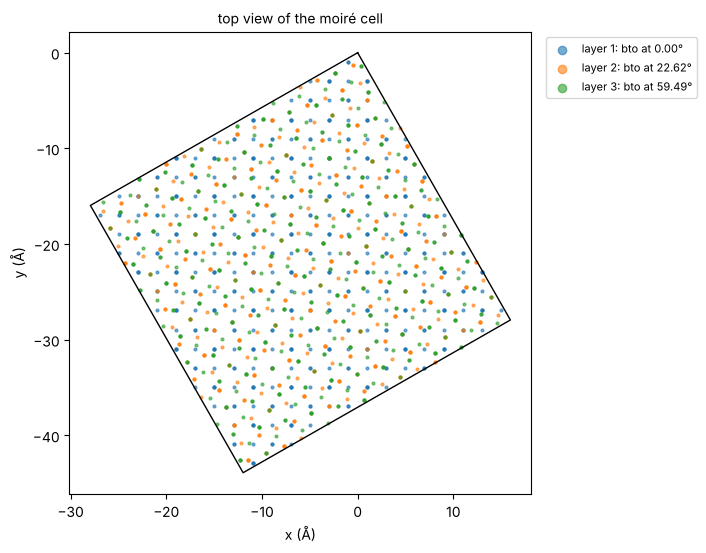

In [11]:
def plot_top_view(record, built):
    fig, ax = plt.subplots(figsize=(6, 6))
    for layer, group in built.atoms.groupby("layer"):
        ax.scatter(group["x"], group["y"], s=4, alpha=0.6,
                   label=f"layer {layer + 1}: {record.material[layer]} at {record.layer_rotations[layer]:.2f}°")
    a1, a2 = record.lattice_vectors
    outline = np.array([[0, 0], a1, a1 + a2, a2, [0, 0]])
    ax.plot(outline[:, 0], outline[:, 1], "k-", lw=1)
    ax.set_aspect("equal")
    ax.set_xlabel("x (Å)")
    ax.set_ylabel("y (Å)")
    ax.set_title("top view of the moiré cell", fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, markerscale=3)
    plt.show()


if chosen is not None:
    built = build_atoms(chosen, search_dirs=[REPO])
    print("atoms per layer:", built.layer_counts, "(expected", built.expected_counts, ")")
    print("composition:", built.composition)
    plot_top_view(chosen, built)

## 6. Write the structure

`INTERLAYER_GAP` is the distance between the highest atom of one layer and the lowest
possible position of the next one; `VACUUM` is added on top of the stack along c.

In [12]:
FORMATS = ["vasp", "lammps"]     # any of "vasp", "lammps"
INTERLAYER_GAP = 3.0             # Å
VACUUM = 50.0                    # Å

if chosen is not None:
    for fmt in FORMATS:
        path = write_structure(run_dir, chosen.id, fmt=fmt, interlayer_gap=INTERLAYER_GAP, vacuum=VACUUM)
        print(f"{fmt:7s} -> {path.relative_to(REPO)}")

vasp    -> runs/my_stack/structures/bto_3_22.62_36.87_015688.vasp


lammps  -> runs/my_stack/structures/bto_3_22.62_36.87_015688.data


## Coming back later

Everything is stored in `runs/<RUN_NAME>/`, so you can come back to any candidate without
searching again:

```python
from MLM.index import find, get, lineage
from MLM.build import write_structure

run_dir = "runs/my_stack"
find(run_dir, n_layers=3, max_layer_residual=1e-3)    # filter the index table
write_structure(run_dir, "<id>", fmt="vasp")         # rebuild any candidate
```

The job itself is saved as `runs/<RUN_NAME>/stack_spec.yaml`. From the repository root,
`python -m MLM run runs/<RUN_NAME>/stack_spec.yaml` repeats it from the command line.